# 01 - Explore Sen1Floods11 chips
Read a chip, confirm band order (VV, VH), and plot VV / VH / label side by side for chips from different countries.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap

ROOT = Path.cwd().parent  # notebook lives in notebooks/
S1_DIR = ROOT / "data" / "s1"
LABEL_DIR = ROOT / "data" / "labels"
print(ROOT, S1_DIR.exists(), LABEL_DIR.exists())

/mnt/d/Projects/College Project/FloodWatch/floodwatch True True


## 1. Read one chip and check the band order

In [2]:
path = sorted(S1_DIR.glob("*_S1Hand.tif"))[0]
with rasterio.open(path) as f:
    img = f.read()
    print(path.name)
    print("shape       :", img.shape)
    print("dtype       :", img.dtype)
    print("descriptions:", f.descriptions)
    print("tags        :", f.tags())
    for i in range(1, f.count + 1):
        print(f"band {i} tags :", f.tags(i))
    print("crs         :", f.crs)

print("NaN pixels per band:", np.isnan(img).sum(axis=(1, 2)))

Bolivia_103757_S1Hand.tif
shape       : (2, 512, 512)
dtype       : float32
descriptions: ('VV', 'VH')
tags        : {'OVR_RESAMPLING_ALG': 'NEAREST', 'AREA_OR_POINT': 'Area'}
band 1 tags : {}
band 2 tags : {}
crs         : EPSG:4326
NaN pixels per band: [160521 160521]


If `descriptions` is `(None, None)`, the file doesn't say. The Sen1Floods11 docs list the S1Hand bands as **VV, VH** (in that order). As a sanity check, VH is normally lower (more negative dB) than VV over land, so its mean should be lower:

In [3]:
print("mean band1 (VV?):", np.nanmean(img[0]))
print("mean band2 (VH?):", np.nanmean(img[1]))

mean band1 (VV?): -13.010354
mean band2 (VH?): -19.286884


## 2. Pick ~6 chips from different countries
One chip per country, preferring chips that actually contain some water so the label panel isn't blank.

In [4]:
rng = np.random.default_rng(0)

by_country = {}
for p in sorted(S1_DIR.glob("*_S1Hand.tif")):
    by_country.setdefault(p.name.split("_")[0], []).append(p)
print({c: len(v) for c, v in by_country.items()})


def label_path(s1_path):
    return LABEL_DIR / s1_path.name.replace("_S1Hand.tif", "_LabelHand.tif")


def pick_chip(paths, min_water=0.05, tries=30):
    """Random chip with at least `min_water` water fraction (falls back to the last try)."""
    for p in rng.permutation(paths)[:tries]:
        with rasterio.open(label_path(p)) as f:
            lab = f.read(1)
        if (lab == 1).mean() >= min_water:
            break
    return p


countries = rng.permutation(sorted(by_country))[:6]
chips = [pick_chip(by_country[c]) for c in countries]
for p in chips:
    print(p.name)

{'Bolivia': 15, 'Ghana': 53, 'India': 68, 'Mekong': 30, 'Nigeria': 18, 'Pakistan': 28, 'Paraguay': 67, 'Somalia': 26, 'Spain': 30, 'Sri-Lanka': 42, 'USA': 69}


Nigeria_600295_S1Hand.tif
Paraguay_605682_S1Hand.tif
Somalia_295782_S1Hand.tif
India_91379_S1Hand.tif
Bolivia_432776_S1Hand.tif
Mekong_1439641_S1Hand.tif


## 3. Plot VV, VH and label side by side

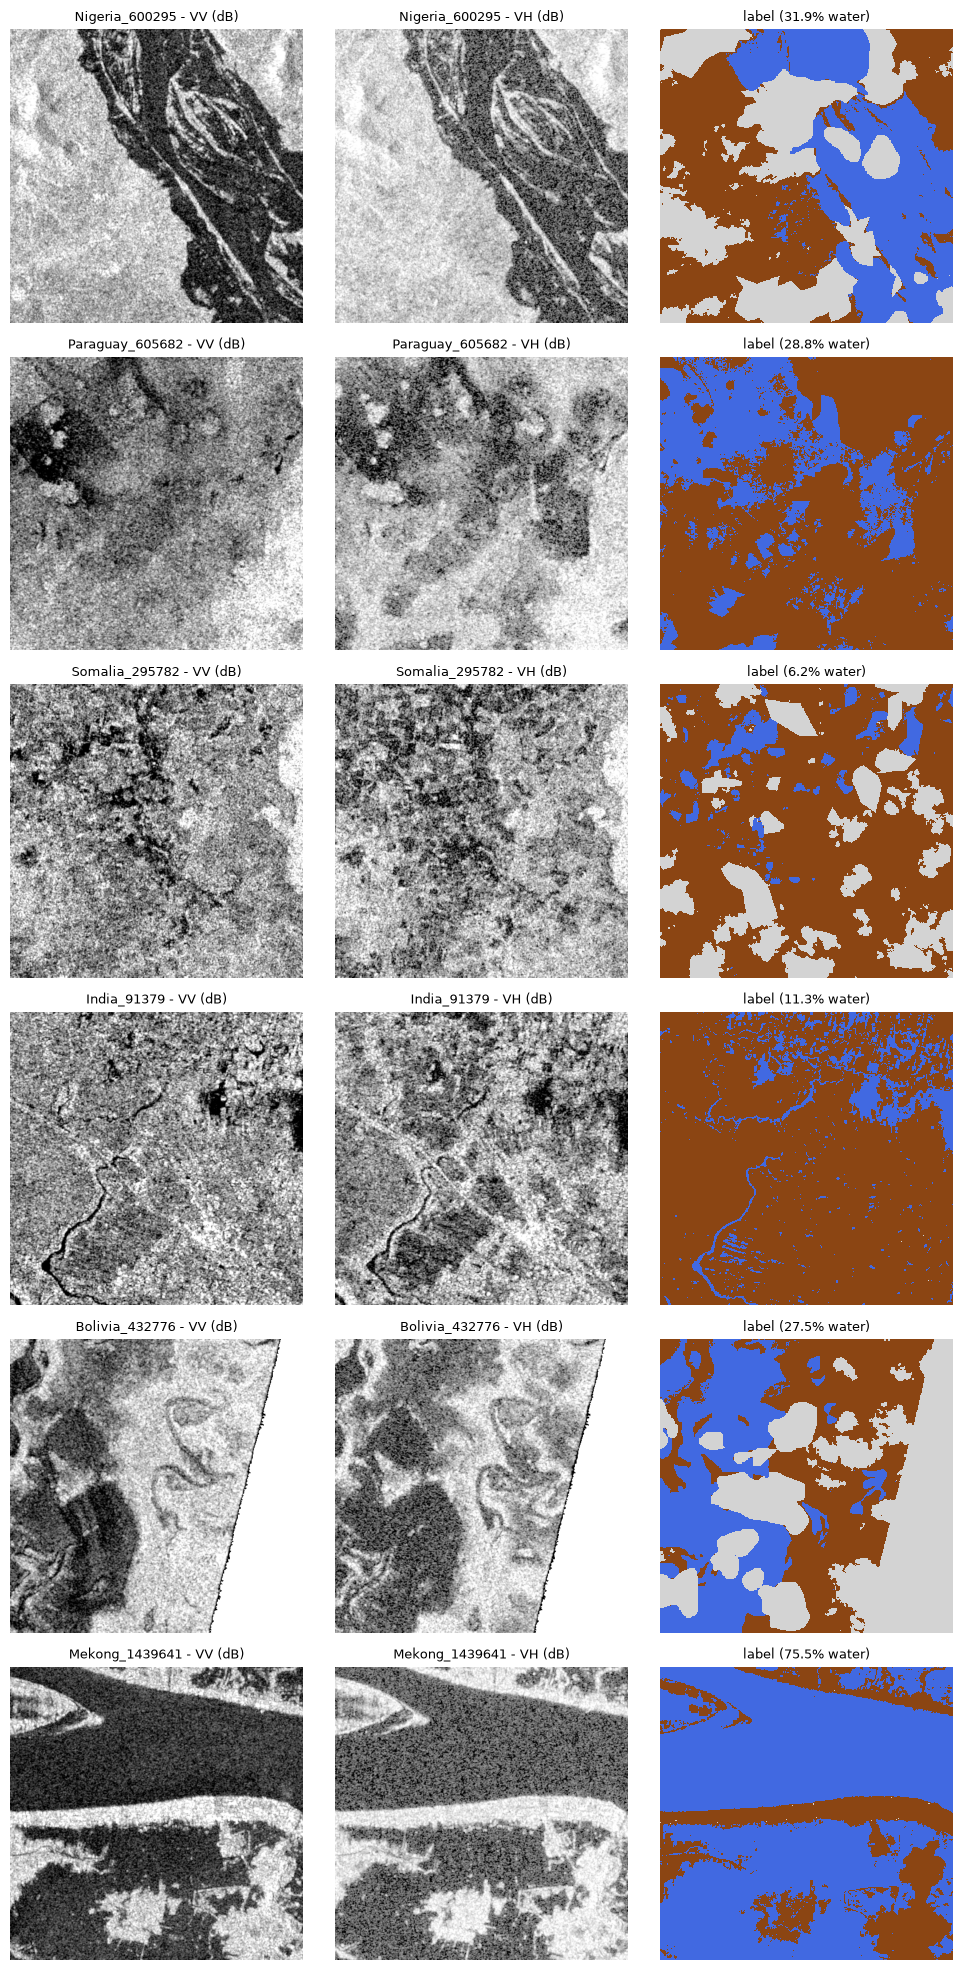

In [5]:
# label values: -1 = no data, 0 = non-water, 1 = water
label_cmap = ListedColormap(["lightgrey", "saddlebrown", "royalblue"])


def show(ax, arr, title, **kw):
    ax.imshow(arr, **kw)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(len(chips), 3, figsize=(10, 3.3 * len(chips)))
for row, p in zip(axes, chips):
    with rasterio.open(p) as f:
        vv, vh = f.read()
    with rasterio.open(label_path(p)) as f:
        lab = f.read(1)

    name = p.name.replace("_S1Hand.tif", "")
    water = 100 * (lab == 1).mean()
    for ax, band, t in zip(row[:2], (vv, vh), ("VV", "VH")):
        lo, hi = np.nanpercentile(band, [2, 98])  # clip outliers for display only
        show(ax, band, f"{name} - {t} (dB)", cmap="gray", vmin=lo, vmax=hi)
    show(row[2], lab, f"label ({water:.1f}% water)", cmap=label_cmap, vmin=-1, vmax=1, interpolation="nearest")

plt.tight_layout()
plt.show()